In [3]:
# Import Neccessary Libraries
# For Data Computation
import numpy as np
import pandas as pd
# For Virsualization
import matplotlib.pyplot
import seaborn as sns
# Logging Libraries
import logging
logging.basicConfig(level = logging.INFO,
                    filename = 'model.log',
                    filemode = 'w',
                    format = "%(asctime)s - %(levelname)s - %(levelname)s",
                    force = True)
# Filter warning messages
import warnings
warnings.filterwarnings(action = 'ignore')
# Set theme
sns.set_theme(style = 'darkgrid')

In [10]:
# ** data ingestion **
filepath = 'C:\supplychain_nalysis\data\SupplyChain_Dataset - SupplyChain_Dataset.csv'
df = pd.read_csv(filepath)
df

,Customer_ID,Customer_Name,Gender,Age,Marital_Status,City,State,Customer_Segment,Membership_Type,Product_ID,...,Available_Stock,Reorder_Level,Reorder_Quantity,Supplier_ID,Supplier_Lead_Time,Purchase_Quantity,Stock_Received,Stockout_Days,Inventory_Turnover,Supply_Status
0,C00165,Payal Gupta,female,61.0,Married,Indore,Madhya Pradesh,Consumer,NaN,P1104,...,102,83,0,S103,NaN,0,0,0.0,11.64,Normal
1,C04625,Rohan Pandey,Male,49.0,Married,Hyderabad,Telangana,Consumer,NaN,P1011,...,144,37,0,S109,13.0,0,0,0.0,6.59,Overstock
2,C03214,Anjali Jain,Female,33.0,Married,Delhi,Delhi,Small Business,Silver,P1029,...,28,41,0,S104,10.0,0,0,0.0,14.26,Understock
3,C00582,Kavya Rao,Female,38.0,Married,Mumbai,Maharashtra,Consumer,Gold,P1048,...,23,16,31,S103,18.0,29,29,0.0,14.05,Normal
4,C01011,Neha Yadav,Female,24.0,Single,Hyderabad,Telangana,Consumer,Platinum,P1030,...,21,30,0,S104,10.0,0,0,0.0,16.48,Understock
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33995,C05034,Farah Malhotra,Female,26.0,Single,Chennai,Tamil Nadu,Consumer,Gold,P1083,...,21,30,0,S104,7.0,0,0,0.0,15.60,Understock
33996,C00081,Meera Menon,Female,30.0,Married,KOLKATA,West Bengal,Consumer,Gold,P1027,...,92,165,540,S102,13.0,533,333,0.0,35.17,Understock
33997,C04618,Payal Kulkarni,F,34.0,Married,Delhi,Delhi,Consumer,Gold,P1111,...,445,100,0,S106,11.0,0,0,0.0,3.81,Overstock
33998,C01036,Sana Pandey,Female,30.0,Married,Pune,Maharashtra,Home Office,Gold,P1107,...,71,41,0,S103,15.0,0,0,0.0,8.44,Normal


In [11]:
#checking dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 34000 entries, 0 to 33999
Data columns (total 52 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Customer_ID              34000 non-null  str    
 1   Customer_Name            34000 non-null  str    
 2   Gender                   34000 non-null  str    
 3   Age                      31966 non-null  float64
 4   Marital_Status           32223 non-null  str    
 5   City                     34000 non-null  str    
 6   State                    34000 non-null  str    
 7   Customer_Segment         34000 non-null  str    
 8   Membership_Type          23744 non-null  str    
 9   Product_ID               34000 non-null  str    
 10  Product_Name             34000 non-null  str    
 11  Category                 34000 non-null  str    
 12  Sub_Category             34000 non-null  str    
 13  Brand                    34000 non-null  str    
 14  Supplier                 34000 no

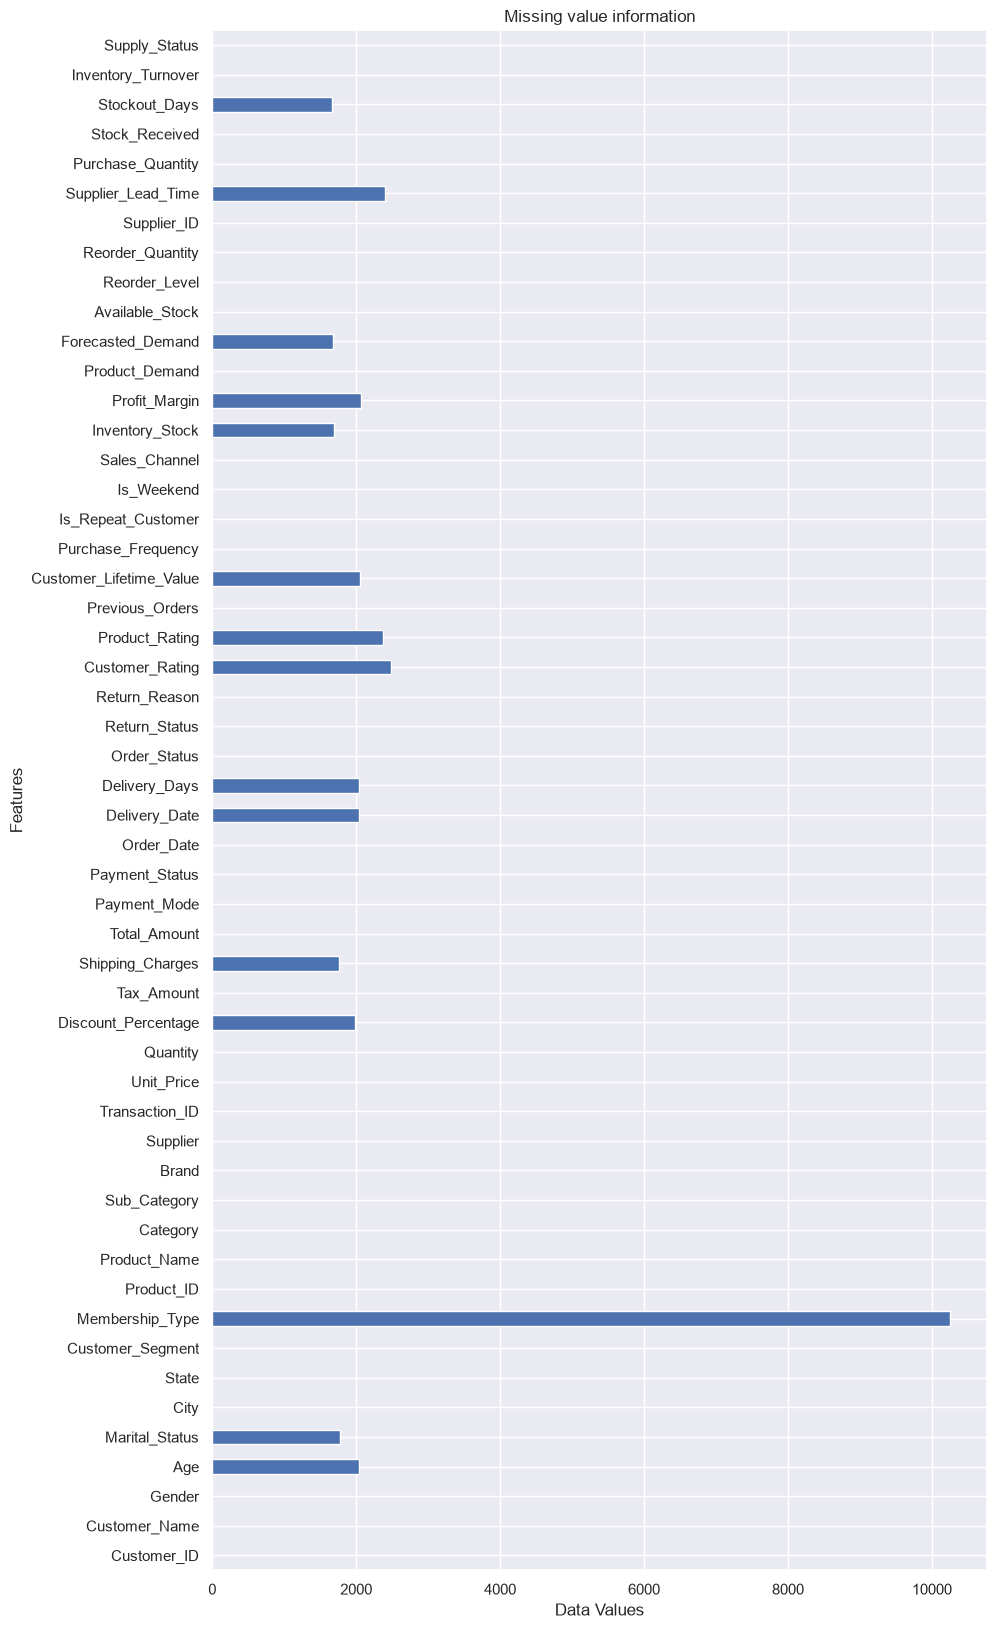

In [13]:
#Checking NULL values in dataset 

import matplotlib.pyplot as plt
plt.figure(figsize = (10,20))
df.isnull().sum().plot(kind = 'barh')
plt.title('Missing value information')
plt.xlabel('Data Values')
plt.ylabel('Features')
plt.show()

In [14]:
df.columns

Index(['Customer_ID', 'Customer_Name', 'Gender', 'Age', 'Marital_Status',
       'City', 'State', 'Customer_Segment', 'Membership_Type', 'Product_ID',
       'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Supplier',
       'Transaction_ID', 'Unit_Price', 'Quantity', 'Discount_Percentage',
       'Tax_Amount', 'Shipping_Charges', 'Total_Amount', 'Payment_Mode',
       'Payment_Status', 'Order_Date', 'Delivery_Date', 'Delivery_Days',
       'Order_Status', 'Return_Status', 'Return_Reason', 'Customer_Rating',
       'Product_Rating', 'Previous_Orders', 'Customer_Lifetime_Value',
       'Purchase_Frequency', 'Is_Repeat_Customer', 'Is_Weekend',
       'Sales_Channel', 'Inventory_Stock', 'Profit_Margin', 'Product_Demand',
       'Forecasted_Demand', 'Available_Stock', 'Reorder_Level',
       'Reorder_Quantity', 'Supplier_ID', 'Supplier_Lead_Time',
       'Purchase_Quantity', 'Stock_Received', 'Stockout_Days',
       'Inventory_Turnover', 'Supply_Status'],
      dtype='str')

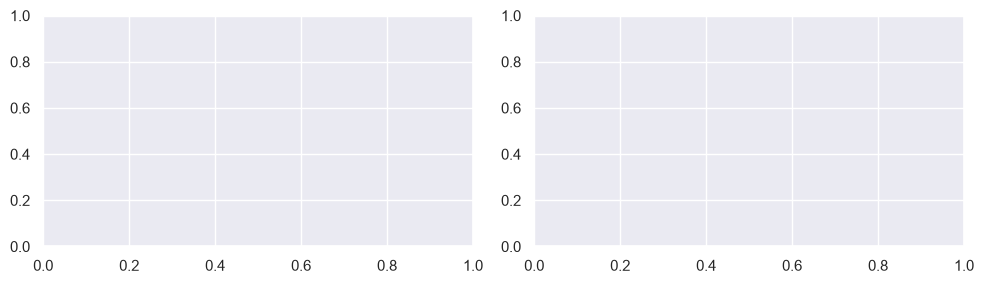

In [ ]:
fig,ax = plt.subplots(1,2,figsize = (10,3))

plt.tight_layout()
plt.show()

In [17]:
df['Gender']

0        female
1          Male
2        Female
3        Female
4        Female
          ...  
33995    Female
33996    Female
33997         F
33998    Female
33999      MALE
Name: Gender, Length: 34000, dtype: str

In [20]:
df['Gender'].unique()
   

<StringArray>
['female',   'Male', 'Female', 'FEMALE',   'male',      'm',      'M',
      'f',  'Other',      'F',   'MALE',  'other']
Length: 12, dtype: str